<a href="https://colab.research.google.com/github/Anmolrbd/ai-ml_bootcamp/blob/main/Assignment%204.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the stroke dataset
data = pd.read_csv("/healthcare-dataset-stroke-data.csv")

print("Dataset dimensions:", data.shape)
display(data.head())

Dataset dimensions: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [9]:

# Check column types and missing values
data.info()

# Count the records in each target category
print("\nStroke cases:")
print(data["stroke"].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

Stroke cases:
stroke
0    4861
1     249
Name: count, dtype: int64


In [10]:

# Examine the distribution of selected variables
features = ["age", "avg_glucose_level", "bmi"]

summary = data[features].describe()
display(summary)


,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,4909.000000
mean,43.226614,106.147677,28.893237
std,22.612647,45.283560,7.854067
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.500000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,33.100000
max,82.000000,271.740000,97.600000


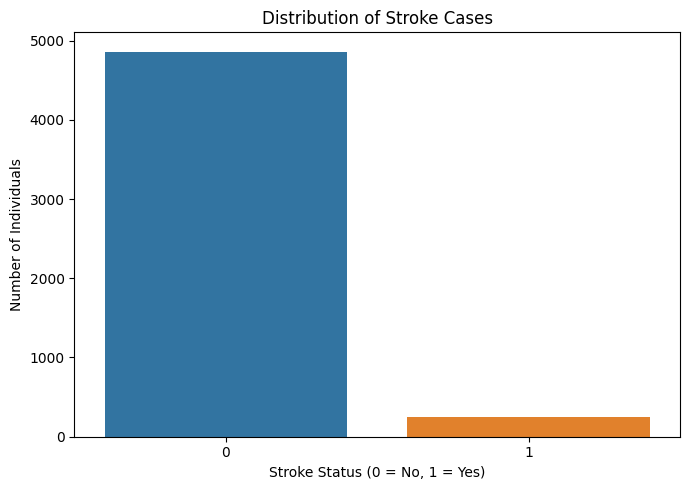

In [11]:

# Compare the number of stroke and non-stroke cases
plt.figure(figsize=(7, 5))

sns.countplot(data=data, x="stroke", hue="stroke", legend=False)

plt.title("Distribution of Stroke Cases")
plt.xlabel("Stroke Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Individuals")
plt.tight_layout()
plt.show()


In [12]:

# Identify the distinct categories in each column
categorical_features = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

for feature in categorical_features:
    print(f"\n{feature}:")
    print(data[feature].unique())



gender:
['Male' 'Female' 'Other']

ever_married:
['Yes' 'No']

work_type:
['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']

Residence_type:
['Urban' 'Rural']

smoking_status:
['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [13]:

# Replace missing BMI values with the median
data["bmi"] = data["bmi"].fillna(data["bmi"].median())

# Exclude records with gender listed as 'Other'
data = data.loc[data["gender"] != "Other"].copy()

# Convert binary categorical features into numeric values
binary_mappings = {
    "gender": {"Male": 1, "Female": 0},
    "ever_married": {"Yes": 1, "No": 0},
    "Residence_type": {"Urban": 1, "Rural": 0}
}

for feature, mapping in binary_mappings.items():
    data[feature] = data[feature].map(mapping)

# Verify that missing values have been handled
print(data.isna().sum())


id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [14]:

# Apply one-hot encoding to multi-category columns
data = pd.get_dummies(
    data,
    columns=["work_type", "smoking_status"],
    drop_first=True,
    dtype=int
)

print("Updated columns:")
print(data.columns.tolist())

print("\nUpdated data types:")
print(data.dtypes)


Updated columns:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'avg_glucose_level', 'bmi', 'stroke', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']

Updated data types:
id                                  int64
gender                              int64
age                               float64
hypertension                        int64
heart_disease                       int64
ever_married                        int64
Residence_type                      int64
avg_glucose_level                 float64
bmi                               float64
stroke                              int64
work_type_Never_worked              int64
work_type_Private                   int64
work_type_Self-employed             int64
work_type_children                  int64
smoking_status_formerly smoked      int64
smoking_status_ne

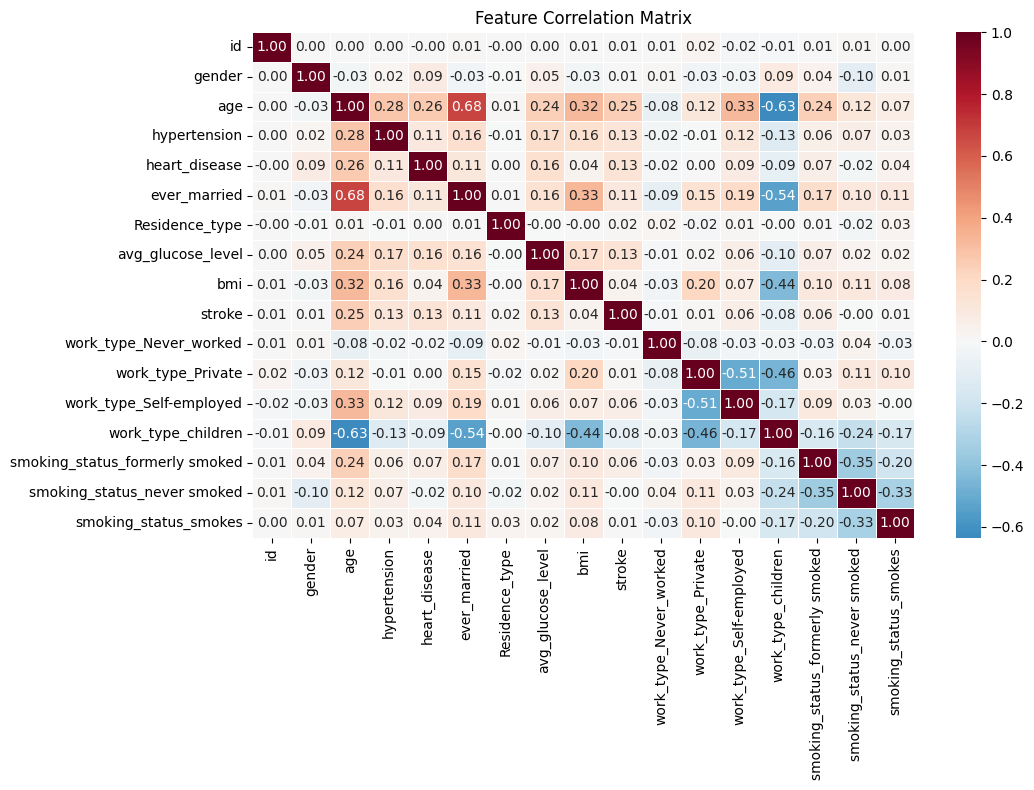

In [15]:

# Calculate correlations between the numerical features
correlation_matrix = data.corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.4
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


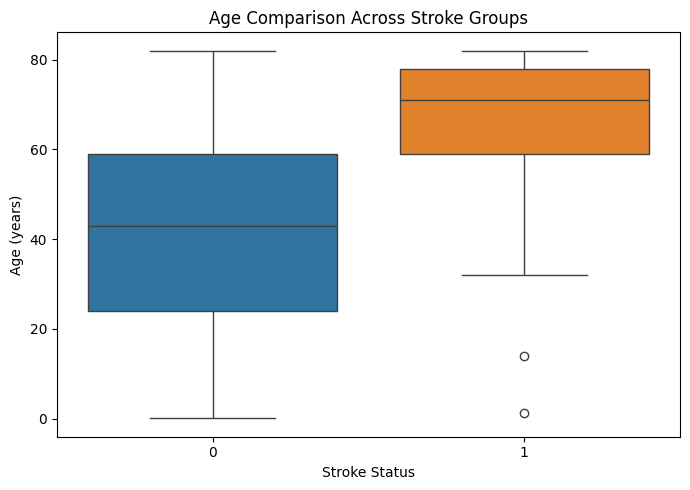

In [16]:

# Compare age distributions across stroke groups
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="stroke", y="age", hue="stroke", legend=False)

plt.title("Age Comparison Across Stroke Groups")
plt.xlabel("Stroke Status")
plt.ylabel("Age (years)")
plt.tight_layout()
plt.show()


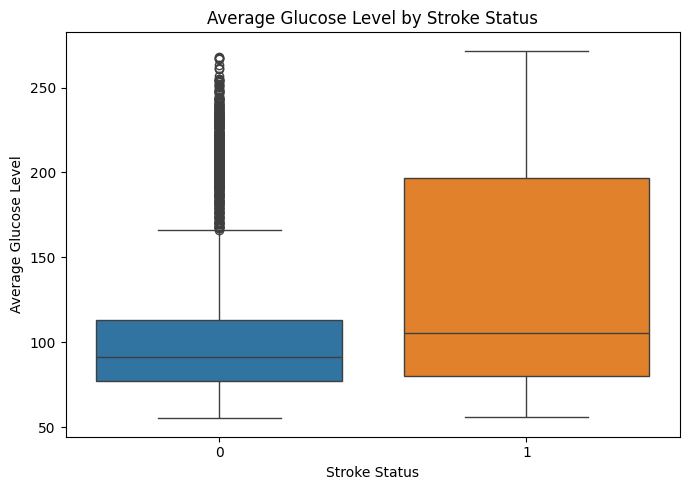

In [17]:

# Examine glucose levels for both groups
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=data,
    x="stroke",
    y="avg_glucose_level",
    hue="stroke",
    legend=False
)

plt.title("Average Glucose Level by Stroke Status")
plt.xlabel("Stroke Status")
plt.ylabel("Average Glucose Level")
plt.tight_layout()
plt.show()


In [18]:

# Calculate stroke proportions within each hypertension group
stroke_proportions = pd.crosstab(
    data["hypertension"],
    data["stroke"],
    normalize="index"
)

print(stroke_proportions)


stroke               0         1
hypertension                    
0             0.960312  0.039688
1             0.867470  0.132530


In [19]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

# Separate predictors from the target variable
X = data.drop(columns=["id", "stroke"])
y = data["stroke"]

# Divide the dataset while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)


Training samples: (4087, 15)
Testing samples: (1022, 15)


In [20]:

# Train a baseline classification model
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

logistic_model.fit(X_train, y_train)

# Generate predictions and probability scores
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, logistic_predictions, zero_division=0))

print("Accuracy:", accuracy_score(y_test, logistic_predictions))
print("Confusion Matrix:\n", confusion_matrix(y_test, logistic_predictions))
print("ROC-AUC:", roc_auc_score(y_test, logistic_probabilities))


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.73      0.84       972
           1       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022

Accuracy: 0.7377690802348337
Confusion Matrix:
 [[714 258]
 [ 10  40]]
ROC-AUC: 0.839238683127572


In [21]:

from sklearn.ensemble import RandomForestClassifier

# Build an ensemble classification model
forest_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)
forest_probabilities = forest_model.predict_proba(X_test)[:, 1]

print("Random Forest Results:")
print(classification_report(y_test, forest_predictions, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, forest_probabilities))


Random Forest Results:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.784619341563786


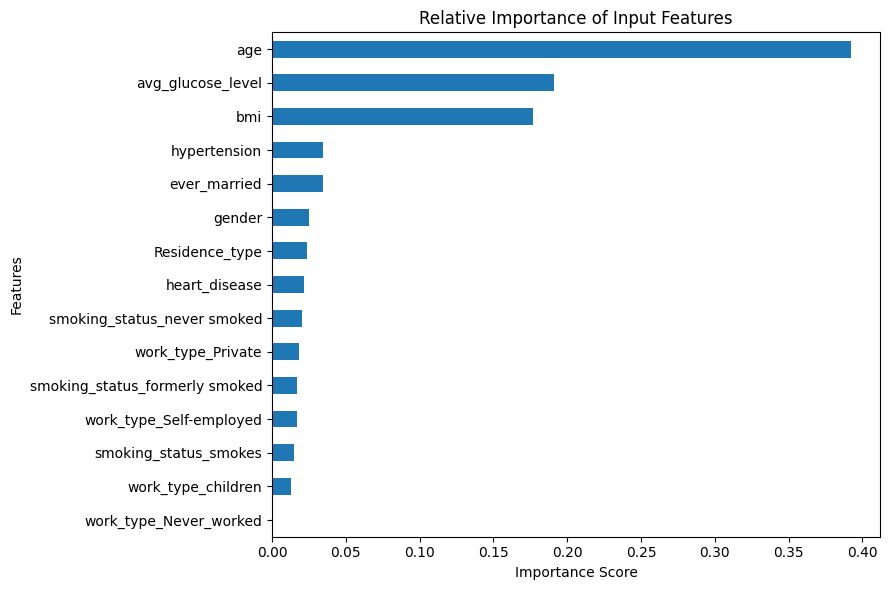

In [22]:

# Rank features according to their contribution to tree splits
feature_ranking = pd.Series(
    forest_model.feature_importances_,
    index=X_train.columns
).sort_values()

plt.figure(figsize=(9, 6))
feature_ranking.plot(kind="barh")

plt.title("Relative Importance of Input Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [23]:

from sklearn.preprocessing import StandardScaler

continuous_features = ["age", "avg_glucose_level", "bmi"]

# Fit the scaler using training data only
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_features] = scaler.fit_transform(
    X_train[continuous_features]
)

X_test_scaled[continuous_features] = scaler.transform(
    X_test[continuous_features]
)

# Fit logistic regression on the scaled dataset
scaled_logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

scaled_logistic_model.fit(X_train_scaled, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000)

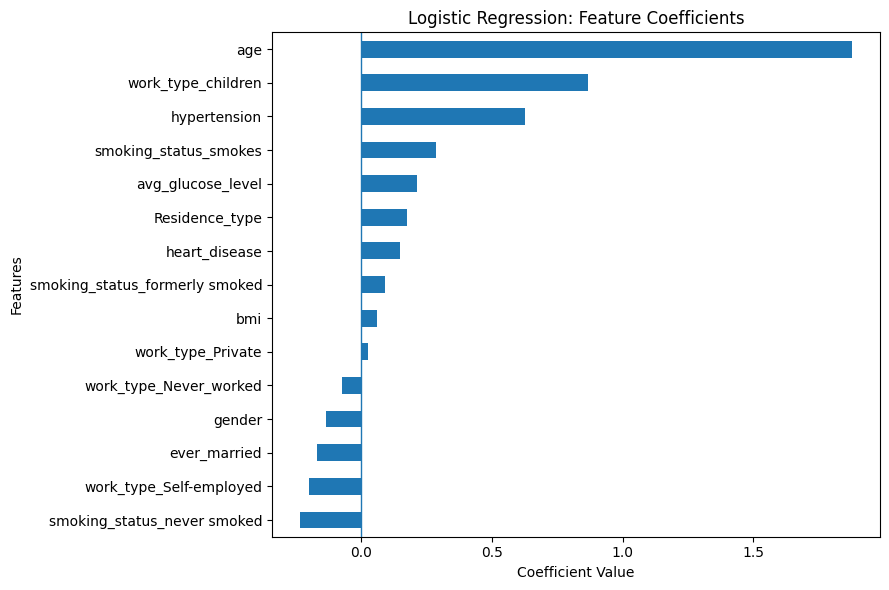

In [24]:

# Extract the fitted model coefficients
coefficient_ranking = pd.Series(
    scaled_logistic_model.coef_[0],
    index=X_train.columns
).sort_values()

plt.figure(figsize=(9, 6))
coefficient_ranking.plot(kind="barh")

plt.axvline(0, linewidth=1)
plt.title("Logistic Regression: Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.tight_layout()
plt.show()
